# Hierarchical

Hierarchical in machine learning typically refers to hierarchical clustering (or hierarchical cluster analysis), an unsupervised learning method that groups data into a tree-like sequence of nested clusters.

# for more information click the link below

https://docs.google.com/document/d/1fjY32E6zS7XHK5GdjmG3vXh4lgelCLY78x1Szwcd5Wk/edit?usp=sharing


# notes and Interview and question and answer. 

https://docs.google.com/document/d/19hfPpt5TPKlo0XZOoGzspTkBGB5COc7aGy8ZL_THNzo/edit?usp=sharing

# Coding

In [5]:
# NumPy → numerical calculations
import numpy as np

# Pandas → data manipulation
import pandas as pd

# Matplotlib → visualization
import matplotlib.pyplot as plt

# Iris dataset → built-in dataset
from sklearn.datasets import load_iris

# StandardScaler → standardizes features
from sklearn.preprocessing import StandardScaler

# AgglomerativeClustering → hierarchical clustering algorithm
from sklearn.cluster import AgglomerativeClustering

# Silhouette Score → evaluates clustering quality
from sklearn.metrics import silhouette_score

# Dendrogram tools → create hierarchical cluster tree
from scipy.cluster.hierarchy import dendrogram, linkage

In [ ]:
# Load the dataset 


iris = load_iris()                       # Loads the Iris dataset

X = iris.data                            # Features used for clustering

y = iris.target                          # True labels, NOT used for training


In [20]:
X.shape

(150, 4)

In [21]:
y.shape

(150,)

In [22]:
# Scale the features 

scaler = StandardScaler()                # Creates the standardization object

X_scaled = scaler.fit_transform(X)                                     # Standardizes all four features

In [24]:
# Create the dendrogram 

linked = linkage(
    X_scaled,                             # Scaled dataset
    method="ward"                         # Merge clusters using Ward's method
)

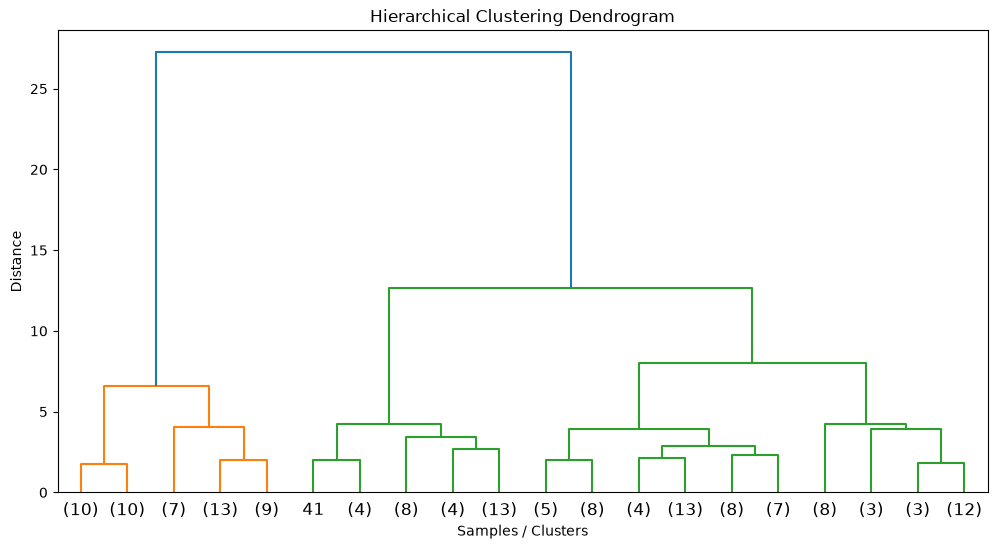

In [14]:
# Now plot 


plt.figure(figsize=(12, 6))

dendrogram(
    linked,                               # Hierarchical clustering information
    truncate_mode="lastp",                # Simplifies the dendrogram for readability
    p=20                                  # Shows the last 20 merged groups
)

plt.xlabel("Samples / Clusters")
plt.ylabel("Distance")
plt.title("Hierarchical Clustering Dendrogram")

plt.show()

In [15]:
hierarchical = AgglomerativeClustering(
    n_clusters=3,                         # Final number of clusters
    metric="euclidean",                   # Distance used between observations
    linkage="ward"                        # Ward linkage minimizes within-cluster variance
)

In [17]:
# Train it: 


clusters = hierarchical.fit_predict(
    X_scaled                              # Learn the hierarchy and return cluster labels
)

# Because this is the unsupervised learning.

In [18]:
# Evaluate the clustering 
# Sihoutte score 
# Just like K-Means, we can use silhouette score. 

silhouette = silhouette_score(
    X_scaled,                             # Feature data
    clusters                              # Cluster assignments
)

print("Silhouette Score:", silhouette)

Silhouette Score: 0.4466890410285909


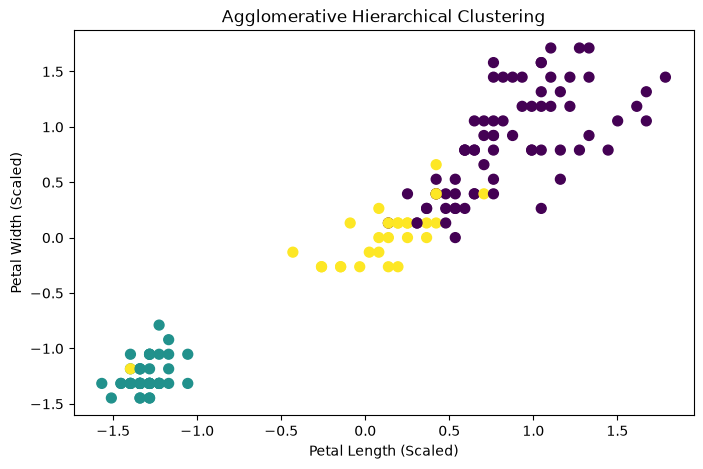

In [19]:
# Higher is generally better . 
# This sllows us to compare differnt cclustering configurations. 

# Visualize the cluster 
# we will use petal length and petal width . 

plt.figure(figsize=(8, 5))

plt.scatter(
    X_scaled[:, 2],                       # Petal length
    X_scaled[:, 3],                       # Petal width
    c=clusters,                           # Color according to cluster
    s=50                                  # Point size
)

plt.xlabel("Petal Length (Scaled)")
plt.ylabel("Petal Width (Scaled)")
plt.title("Agglomerative Hierarchical Clustering")

plt.show()


In [25]:
# Differnet number of cluster 

results = []                              # Stores results for each K

for k in range(2, 8):

    model = AgglomerativeClustering(
        n_clusters=k,                     # Test a different number of clusters
        metric="euclidean",               # Euclidean distance
        linkage="ward"                    # Ward linkage
    )

    labels = model.fit_predict(
        X_scaled                           # Perform hierarchical clustering
    )

    score = silhouette_score(
        X_scaled,                          # Dataset
        labels                             # Cluster assignments
    )

    results.append(
        [k, score]                         # Store K and its Silhouette Score
    )

results_df = pd.DataFrame(
    results,
    columns=["n_clusters", "silhouette_score"]
)

print(results_df)

   n_clusters  silhouette_score
0           2          0.577035
1           3          0.446689
2           4          0.400636
3           5          0.330587
4           6          0.314855
5           7          0.316970


In [26]:
# So for the non-ward methods, we wil use euclidean as well . 

linkage_methods = [
    "ward",
    "complete",
    "average",
    "single"
]

for method in linkage_methods:

    model = AgglomerativeClustering(
        n_clusters=3,                     # Keep K fixed so we compare linkage fairly
        metric="euclidean",               # Use Euclidean distance
        linkage=method                    # Change the linkage strategy
    )

    labels = model.fit_predict(
        X_scaled                           # Perform clustering
    )

    score = silhouette_score(
        X_scaled,                          # Dataset
        labels                             # Cluster assignments
    )

    print(
        f"{method}: {score:.3f}"           # Display Silhouette Score
    )


ward: 0.447
complete: 0.450
average: 0.480
single: 0.505
